In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn xlrd

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the dataset
df = pd.read_excel(
    "default of credit card clients.xls",
    header=1
)

# Display the first five rows
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (30000, 25)

Column Names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 

In [5]:
target = "default payment next month"

# Count the number of each outcome
print(df[target].value_counts())

# Calculate percentages
print("\nTarget Distribution (%):")
print(df[target].value_counts(normalize=True) * 100)

default payment next month
0    23364
1     6636
Name: count, dtype: int64

Target Distribution (%):
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


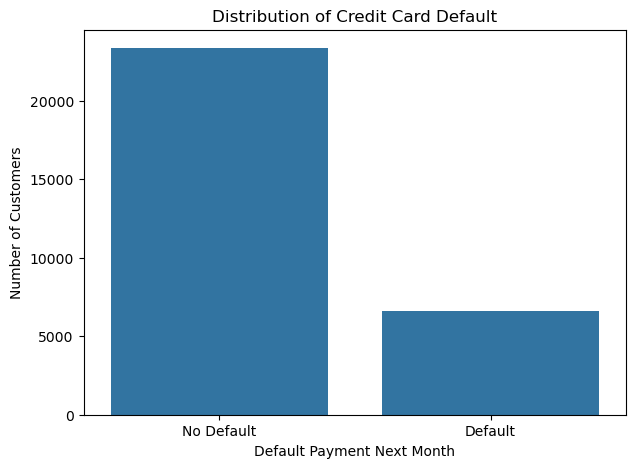

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=target
)

plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Payment Next Month")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["No Default", "Default"])

plt.show()

In [7]:
# Separate features and target
X = df.drop(columns=["ID", target])
y = df[target]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (30000, 23)
Target Shape: (30000,)

Target Distribution:
default payment next month
0    23364
1     6636
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Set: (24000, 23)
Testing Set: (6000, 23)

Training Target Distribution:
default payment next month
0    0.778792
1    0.221208
Name: proportion, dtype: float64

Testing Target Distribution:
default payment next month
0    0.778833
1    0.221167
Name: proportion, dtype: float64


In [9]:

# Define categorical and numerical columns
categorical_cols = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

# Apply one-hot encoding
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Make sure training and testing have the same columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Standardize numerical variables
scaler = StandardScaler()

X_train_encoded[numerical_cols] = scaler.fit_transform(
    X_train_encoded[numerical_cols]
)

X_test_encoded[numerical_cols] = scaler.transform(
    X_test_encoded[numerical_cols]
)

print("Preprocessing completed!")
print("Processed Training Set:", X_train_encoded.shape)
print("Processed Testing Set:", X_test_encoded.shape)


Preprocessing completed!
Processed Training Set: (24000, 82)
Processed Testing Set: (6000, 82)


In [10]:
print("Final Training Data:")
print(X_train_encoded.head())

print("\nFinal Testing Data:")
print(X_test_encoded.head())

print("\nMissing Values in Training Data:")
print(X_train_encoded.isnull().sum().sum())

print("\nMissing Values in Testing Data:")
print(X_test_encoded.isnull().sum().sum())

Final Training Data:
       LIMIT_BAL       AGE  BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  \
22788  -0.056866 -0.264558   1.505547   1.745089   1.778869   1.891679   
29006  -0.134081 -0.155804  -0.695165  -0.691138  -0.685090  -0.673845   
16950  -1.215090  1.584260  -0.556800  -0.576836  -0.561615  -0.547887   
22280   0.406423 -0.699574   2.119190   2.287237   2.460102   2.738001   
11346   1.101358 -0.373312  -0.695165  -0.691886  -0.680324  -0.668755   

       BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  ...  PAY_5_8  PAY_6_-1  \
22788   2.020839   2.096346  0.580657 -0.290332  ...        0         0   
29006  -0.662488  -0.652126 -0.344969 -0.290332  ...        0         0   
16950  -0.526789  -0.510492 -0.348128 -0.227081  ...        0         0   
22280   1.509166   1.613118  0.215287  0.154056  ...        0         0   
11346  -0.666365  -0.656089 -0.348251 -0.274236  ...        0         0   

       PAY_6_0  PAY_6_2  PAY_6_3  PAY_6_4  PAY_6_5  PAY_6_6  PAY_6_7  PAY_6_8  
227

## Bayesian Logistic Regression

For this project, we will first use Bayesian Logistic Regression to predict whether a credit card customer will default next month. The model will use the customer information and repayment history in the dataset to estimate the probability of default.

After fitting the model, we will check how well its predictions match the actual results in the test set. Since the dataset contains fewer default cases than non-default cases, we will also pay attention to how well the model identifies customers who actually default.

In [11]:
!pip install pymc arviz

In [12]:
# Bayesian Logistic Regression

import pymc as pm
from scipy.special import expit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Convert data to NumPy arrays
X_train_np = X_train_encoded.to_numpy(dtype=float)
X_test_np = X_test_encoded.to_numpy(dtype=float)

y_train_np = y_train.to_numpy(dtype=int)
y_test_np = y_test.to_numpy(dtype=int)

# Build the Bayesian Logistic Regression model
with pm.Model() as bayesian_logistic_model:

    # Prior distributions
    alpha = pm.Normal("alpha", mu=0, sigma=2.5)
    beta = pm.Normal(
        "beta",
        mu=0,
        sigma=1,
        shape=X_train_np.shape[1]
    )

    # Logistic regression
    logits = alpha + pm.math.dot(X_train_np, beta)

    # Bernoulli likelihood
    y_obs = pm.Bernoulli(
        "y_obs",
        logit_p=logits,
        observed=y_train_np
    )

    # Approximate posterior inference using ADVI
    approx = pm.fit(
        n=15000,
        method="advi",
        random_seed=42,
        progressbar=True
    )

    # Draw samples from the approximate posterior
    idata = approx.sample(1000, random_seed=42)

print("Bayesian Logistic Regression completed!")


Output()

Finished [100%]: Average Loss = 11,338


Bayesian Logistic Regression completed!


In [13]:
# Extract posterior samples
alpha_samples = np.asarray(
    idata.posterior["alpha"]
).reshape(-1)

beta_samples = np.asarray(
    idata.posterior["beta"]
).reshape(-1, X_train_np.shape[1])

# Calculate predicted probabilities for the test set
logits_test = (
    alpha_samples[:, None]
    + beta_samples @ X_test_np.T
)

probability_samples = expit(logits_test)

# Average posterior probabilities
y_pred_proba = probability_samples.mean(axis=0)

# Convert probabilities into class predictions
y_pred = (y_pred_proba >= 0.5).astype(int)

print("Prediction completed!")
print("Number of predictions:", len(y_pred))

Prediction completed!
Number of predictions: 6000


In [14]:
accuracy = accuracy_score(y_test_np, y_pred)
precision = precision_score(y_test_np, y_pred, zero_division=0)
recall = recall_score(y_test_np, y_pred, zero_division=0)
f1 = f1_score(y_test_np, y_pred, zero_division=0)
auc = roc_auc_score(y_test_np, y_pred_proba)

print("Bayesian Logistic Regression Results")
print("------------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_np,
    y_pred,
    target_names=["No Default", "Default"],
    zero_division=0
))


Bayesian Logistic Regression Results
------------------------------------
Accuracy:  0.8172
Precision: 0.6624
Recall:    0.3534
F1 Score:  0.4609
ROC-AUC:   0.7622

Classification Report:
              precision    recall  f1-score   support

  No Default       0.84      0.95      0.89      4673
     Default       0.66      0.35      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.68      6000
weighted avg       0.80      0.82      0.80      6000



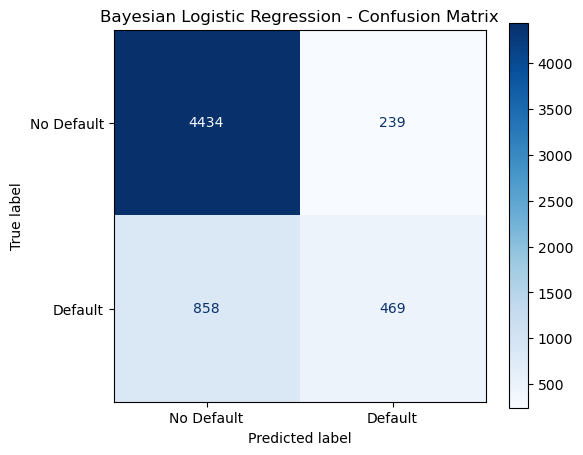

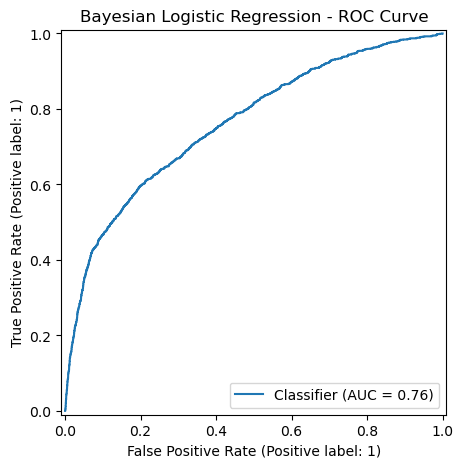

In [15]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_np,
    y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    ax=ax
)

plt.title("Bayesian Logistic Regression - Confusion Matrix")
plt.show()


# ROC Curve
fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_test_np,
    y_pred_proba,
    ax=ax
)

plt.title("Bayesian Logistic Regression - ROC Curve")
plt.show()